# Scaler Learner Salary Clustering

## 1. Problem statement
Scaler wants to understand **how its learners are distributed across salary and experience levels** so it can
design better programs, benchmark salaries and target career services. The dataset holds one row per
CTC (annual compensation, in INR) update per learner, with the employer (`company_hash`, anonymised), the learner's
job role, the year they joined the workforce (`orgyear`) and the year the CTC was last updated (`ctc_updated_year`).

**Objectives**
1. Explore and clean the data (EDA, regex cleaning of company names, outlier handling, KNN imputation, encoding, scaling).
2. Build **manual clustering flags** — *Designation* (company + role + experience), *Class* (company + role) and *Tier* (company) —
   by comparing every learner's CTC with the mean CTC of their group.
3. Run **unsupervised learning** (clustering tendency, elbow, silhouette, K-Means, hierarchical) to find learner segments.
4. Turn the findings into **actionable business recommendations**.

**Additional views (beyond the brief)**
- Which roles and experience bands command the highest pay, and how reliable are those numbers?
- Is the data trustworthy enough to benchmark salaries (outliers, stale records, repeated learners)?
- Which segments should Scaler target with which programs?

## 2. Key modelling decisions (and why)
| Decision | Reason |
|---|---|
| `REFERENCE_YEAR = 2021` | `ctc_updated_year` ends in 2021, so experience = 2021 − `orgyear`. |
| Company names cleaned with regex | Raw `company_hash` contains junk values such as `2016`, `2019`, `20152019`, stray spaces and punctuation. |
| One record per learner (latest CTC update) | ~93k rows share an email hash with another row; counting rows as learners overstates segment sizes. Controlled by `DEDUPLICATE_LEARNERS`. |
| CTC outliers removed with the IQR rule on **log10(CTC)** | CTC is extremely right-skewed (values from ₹2 to ₹100 crore); a plain IQR rule would wrongly cut normal high earners. |
| Outlier / missing CTC is **not** used for salary benchmarking, but **KNN-imputed** for clustering only | Keeps benchmarks honest while giving the clustering a complete matrix. |
| Hierarchical clustering on a sample | Ward linkage needs O(n²) memory. |

## Step 1 — Import libraries

In [ ]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import dendrogram, linkage

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

# ---- Configuration -----------------------------------------------------
RANDOM_STATE = 42
REFERENCE_YEAR = 2021
MIN_VALID_ORGYEAR = 1980
DEDUPLICATE_LEARNERS = True      # keep only the latest CTC record per learner
IQR_MULTIPLIER = 1.5             # outlier rule applied on log10(CTC)
MIN_GROUP_SIZE = 3               # minimum peers needed to create a manual flag
MIN_COMPANY_RECORDS = 20         # minimum records for company rankings
K_FINAL = None                   # set to an integer to override the silhouette-chosen K

lakh = lambda x: x / 1e5         # helper: INR -> lakh
print("Libraries imported successfully.")

Libraries imported successfully.


## Step 2 — Load the dataset (works in Google Colab and locally)

In [ ]:
import os

DATA_FILE = "scaler_hashed_for_students.csv"
if not os.path.exists(DATA_FILE):
    try:
        from google.colab import files          # Colab: ask for the file
        uploaded = files.upload()
        DATA_FILE = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError(f"Place '{DATA_FILE}' next to this notebook and re-run.")

raw_df = pd.read_csv(DATA_FILE)
print("Original dataset shape:", raw_df.shape)
display(raw_df.head())

Saving scaler_hashed_for_students.csv to scaler_hashed_for_students.csv
Original dataset shape: (205843, 7)


,Unnamed: 0,company_hash,email_hash,orgyear,ctc,job_position,ctc_updated_year
0,0,czniswwz sucsk,6de0a4417d18ab14334c3f43397fc13b30c35149d70c05...,2016.00,1100000,Other,2020.00
1,1,oznskulz subilihh nshswzc,b0aaf1ac138b53cb6e039ba2c3d6604a250d02d5145c10...,2018.00,449999,FullStack Engineer,2019.00
2,2,faulwklwsl ks,4860c670bcd48fb96c02a4b0ae3608ae6fdd98176112e9...,2015.00,2000000,Backend Engineer,2020.00
3,3,wirijzcsk,effdede7a2e7c2af664c8a31d9346385016128d66bbc58...,2017.00,700000,Backend Engineer,2019.00
4,4,osbw toidj,6ff54e709262f55cb999a1c1db8436cb2055d8f79ab520...,2017.00,1400000,FullStack Engineer,2019.00


## Part A — Exploratory Data Analysis (on the raw data)
### Step 3 — Shape, data types, missing values and statistical summary

In [ ]:
eda_df = raw_df.copy()
eda_df.columns = eda_df.columns.str.strip().str.lower()
eda_df = eda_df.drop(columns=[c for c in eda_df.columns if c.startswith("unnamed")])   # index artefact

print("Shape:", eda_df.shape)
print("\nData types:")
display(eda_df.dtypes.to_frame("dtype"))

# Convert true categorical attributes to the 'category' dtype
for c in ["company_hash", "job_position"]:
    eda_df[c] = eda_df[c].astype("category")
print("\nData types after converting categorical attributes:")
display(eda_df.dtypes.to_frame("dtype"))

print("Exact duplicate rows:", eda_df.duplicated().sum())
print("Unique email hashes (learners):", eda_df["email_hash"].nunique())
print("Rows sharing an email hash with another row:", eda_df["email_hash"].duplicated(keep=False).sum())

missing = pd.DataFrame({"Missing_Count": eda_df.isna().sum(),
                        "Missing_%": eda_df.isna().mean() * 100}).sort_values("Missing_%", ascending=False)
print("\nMissing values:")
display(missing)

print("Numeric summary:")
display(eda_df[["orgyear", "ctc", "ctc_updated_year"]].describe().T)
print("Categorical summary:")
display(eda_df[["company_hash", "job_position"]].describe().T)

Shape: (205843, 6)

Data types:


,dtype
company_hash,object
email_hash,object
orgyear,float64
ctc,int64
job_position,object
ctc_updated_year,float64



Data types after converting categorical attributes:


,dtype
company_hash,category
email_hash,object
orgyear,float64
ctc,int64
job_position,category
ctc_updated_year,float64


Exact duplicate rows: 34
Unique email hashes (learners): 153443
Rows sharing an email hash with another row: 93616

Missing values:


,Missing_Count,Missing_%
job_position,52564,25.54
orgyear,86,0.04
company_hash,44,0.02
email_hash,0,0.00
ctc,0,0.00
ctc_updated_year,0,0.00


Numeric summary:


,count,mean,std,min,25%,50%,75%,max
orgyear,205757.00,2014.88,63.57,0.00,2013.00,2016.00,2018.00,20165.00
ctc,205843.00,2271685.04,11800914.44,2.00,530000.00,950000.00,1700000.00,1000150000.00
ctc_updated_year,205843.00,2019.63,1.33,2015.00,2019.00,2020.00,2021.00,2021.00


Categorical summary:


,count,unique,top,freq
company_hash,205799,37299,wkwk liufdnwkula fzovslzf,8337
job_position,153279,1016,Backend Engineer,43554


**Observations — structure & quality**
- The raw file has **205,843 rows × 7 columns** (after dropping the unnamed index column: 6 analytical columns). `company_hash`, `email_hash` and `job_position` are text; `orgyear`, `ctc`, `ctc_updated_year` are numeric.
- `job_position` is missing for about **25.5%** of rows, `orgyear` for ~0.04% and `company_hash` for ~0.02%. `ctc` has no nulls but contains impossible values.
- **Range problems:** `orgyear` runs from 0 to 20,165 (clearly invalid); `ctc` runs from ₹2 to about ₹100 crore, while the median is only ~₹9.5 lakh and the mean ~₹22.7 lakh. `ctc_updated_year` is clean (2015–2021, median 2020).
- There are no exact duplicate rows, but the number of unique email hashes is far smaller than the number of rows, so **many learners appear more than once** (one row per CTC update).

### Step 4 — Univariate analysis

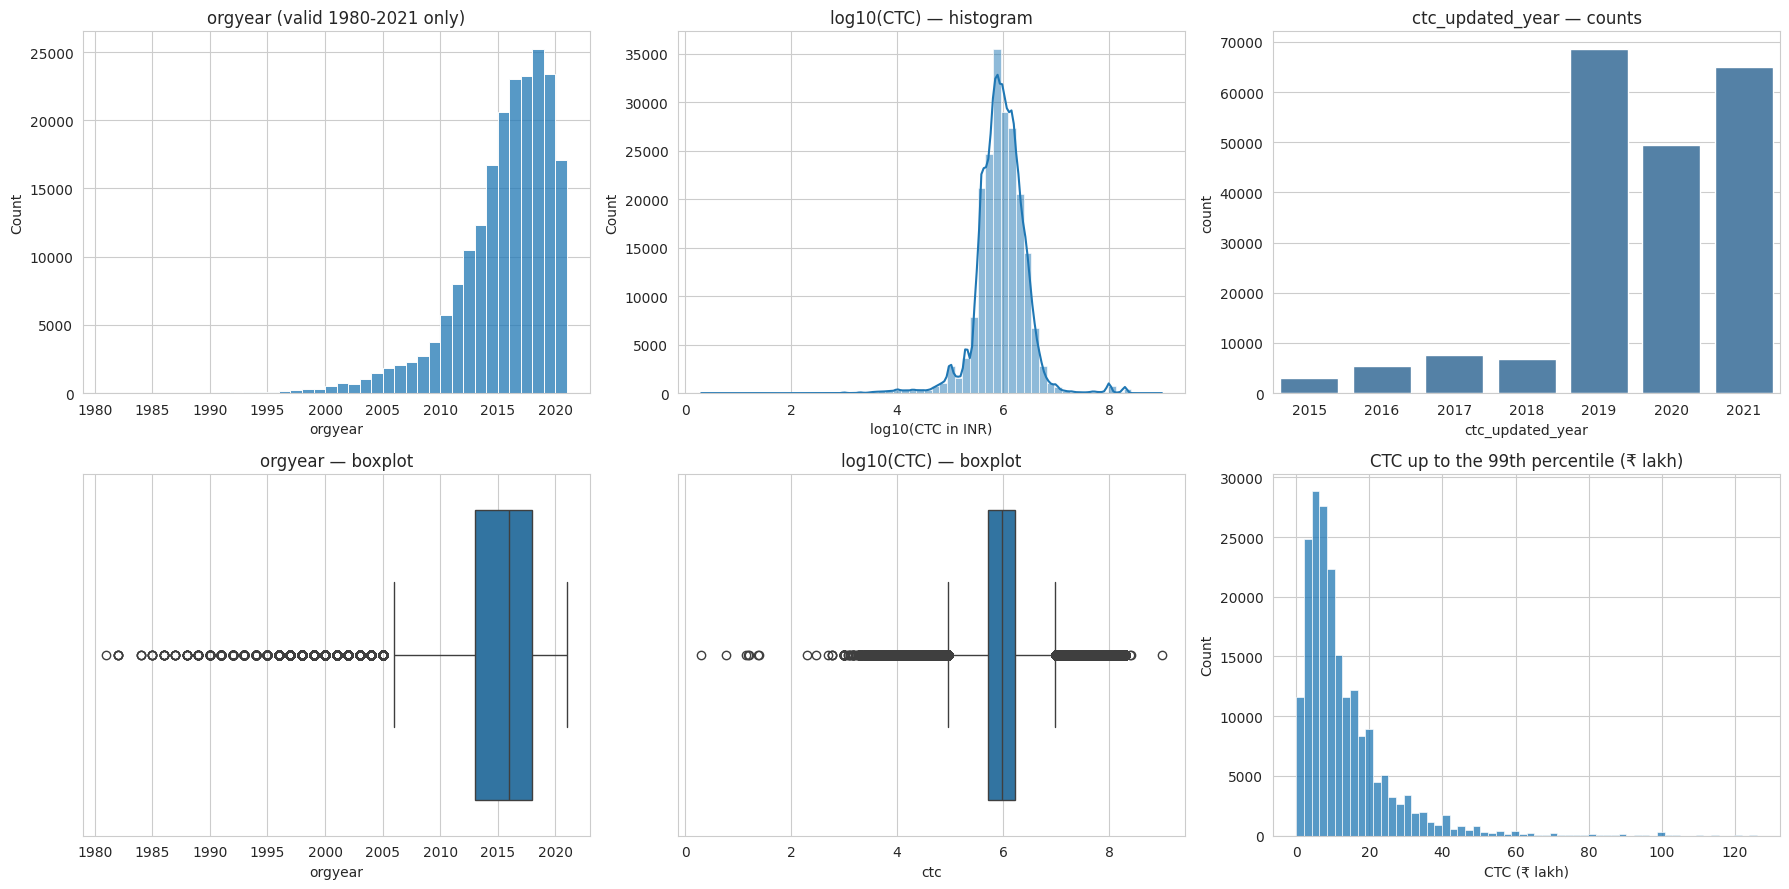

Skewness  orgyear (valid): -1.55 | CTC raw: 15.97 | log10 CTC: -0.24 | ctc_updated_year: -1.18
CTC percentiles (₹ lakh):


,CTC_lakh
0.00,0.04
0.01,0.37
0.05,2.00
0.25,5.30
0.50,9.50
0.75,17.00
0.95,38.00
0.99,126.00
1.00,2000.00


In [ ]:
valid_org = eda_df.loc[eda_df["orgyear"].between(MIN_VALID_ORGYEAR, REFERENCE_YEAR), "orgyear"]
ctc_pos = eda_df.loc[eda_df["ctc"] > 0, "ctc"]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))

sns.histplot(valid_org, bins=40, ax=axes[0, 0])
axes[0, 0].set_title(f"orgyear (valid {MIN_VALID_ORGYEAR}-{REFERENCE_YEAR} only)")

sns.boxplot(x=valid_org, ax=axes[1, 0])
axes[1, 0].set_title("orgyear — boxplot")

sns.histplot(np.log10(ctc_pos), bins=60, kde=True, ax=axes[0, 1])
axes[0, 1].set_title("log10(CTC) — histogram")
axes[0, 1].set_xlabel("log10(CTC in INR)")

sns.boxplot(x=np.log10(ctc_pos), ax=axes[1, 1])
axes[1, 1].set_title("log10(CTC) — boxplot")

sns.countplot(x=eda_df["ctc_updated_year"].astype("Int64"), ax=axes[0, 2], color="steelblue")
axes[0, 2].set_title("ctc_updated_year — counts")

sns.histplot(ctc_pos[ctc_pos <= ctc_pos.quantile(0.99)] / 1e5, bins=60, ax=axes[1, 2])
axes[1, 2].set_title("CTC up to the 99th percentile (₹ lakh)")
axes[1, 2].set_xlabel("CTC (₹ lakh)")
plt.tight_layout()
plt.show()

print("Skewness  orgyear (valid):", round(valid_org.skew(), 2),
      "| CTC raw:", round(ctc_pos.skew(), 2),
      "| log10 CTC:", round(np.log10(ctc_pos).skew(), 2),
      "| ctc_updated_year:", round(eda_df['ctc_updated_year'].skew(), 2))
print("CTC percentiles (₹ lakh):")
display((ctc_pos.quantile([0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]) / 1e5).to_frame("CTC_lakh"))

**Comments on the continuous-variable plots**
- **`orgyear`** — after restricting to 1980–2021, joining years are left-skewed: most learners joined recently (median ≈ 2016), with a thin tail of very experienced people. The boxplot shows older joining years as low-side outliers, but those are genuine senior professionals, not errors. Values such as 0 or 20,165 are data-entry errors and are removed in cleaning.
- **`ctc` (raw)** is extremely right-skewed (skewness ≈ 16). On a log10 scale the distribution is close to bell-shaped, which confirms that **salary should be modelled on the log scale**. The boxplot of log10(CTC) exposes outliers at *both* ends — implausibly tiny salaries (₹2 to a few thousand) and absurdly large ones (up to ₹100 crore).
- **`ctc_updated_year`** is concentrated in 2019–2021, so the dataset reflects mostly recent salary updates; older years (2015–2017) form the "stale" tail.

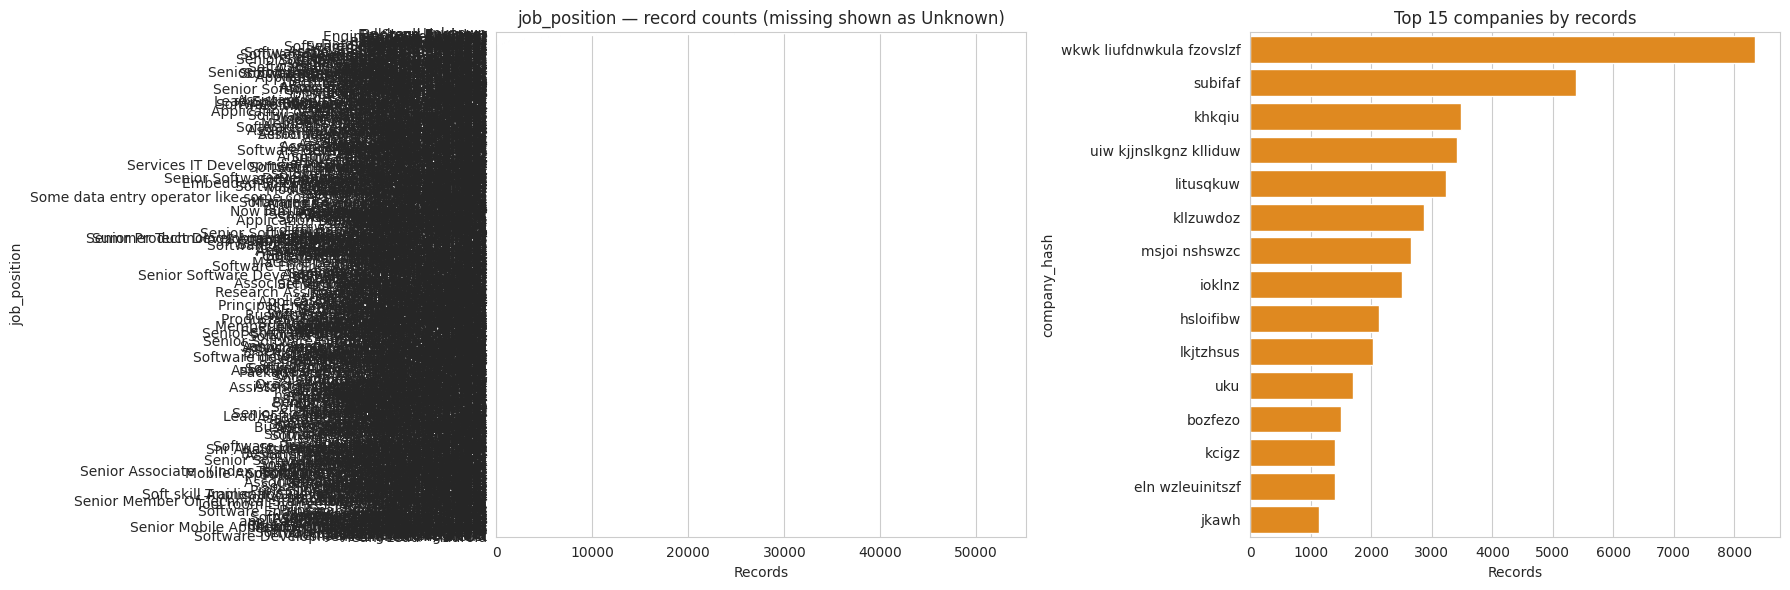

Distinct job positions: 1016 | distinct company_hash values: 37299
Share of records from the top 15 companies: 21.0%


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

order = eda_df["job_position"].value_counts(dropna=False).index
pos_counts = eda_df["job_position"].astype(object).fillna("Unknown").value_counts()
sns.barplot(x=pos_counts.values, y=pos_counts.index, ax=axes[0], color="steelblue")
axes[0].set_title("job_position — record counts (missing shown as Unknown)")
axes[0].set_xlabel("Records")

top_comp = eda_df["company_hash"].astype(object).value_counts().head(15)
sns.barplot(x=top_comp.values, y=top_comp.index, ax=axes[1], color="darkorange")
axes[1].set_title("Top 15 companies by records")
axes[1].set_xlabel("Records")
plt.tight_layout()
plt.show()

print("Distinct job positions:", eda_df["job_position"].nunique(),
      "| distinct company_hash values:", eda_df["company_hash"].nunique())
print("Share of records from the top 15 companies: %.1f%%" %
      (100 * top_comp.sum() / len(eda_df)))

**Comments on the categorical plots**
- `job_position` is dominated by **Backend Engineer (~21%)**, followed by Full-Stack, Other, Frontend, Engineering Leadership, QA, Data Scientist, Android and SDET. The single largest bucket is actually **missing/Unknown (~25.5%)**, which limits any role-level conclusion.
- Data Scientist is only ~2.6% of records, so role-level statistics for data science rest on a comparatively small sample.
- Company records are long-tailed: a handful of employers contribute thousands of records each while the vast majority contribute very few, which is why company-level statistics need a **minimum-sample rule**.

### Step 5 — Bivariate analysis

In [ ]:
# Work on a temporary frame with plausible values so the plots are readable
bv = eda_df.copy()
bv["job_position"] = bv["job_position"].astype(object).fillna("Unknown")
bv = bv[bv["orgyear"].between(MIN_VALID_ORGYEAR, REFERENCE_YEAR) & (bv["ctc"] > 0)].copy()
bv["exp"] = REFERENCE_YEAR - bv["orgyear"]
bv["log_ctc"] = np.log10(bv["ctc"])
bv_trim = bv[bv["ctc"].between(bv["ctc"].quantile(0.01), bv["ctc"].quantile(0.99))]

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

role_order = bv_trim.groupby("job_position")["ctc"].median().sort_values(ascending=False).index
sns.boxplot(data=bv_trim, y="job_position", x=bv_trim["ctc"] / 1e5, order=role_order,
            showfliers=False, ax=axes[0, 0])
axes[0, 0].set_title("CTC by job position (1st-99th percentile, ₹ lakh)")
axes[0, 0].set_xlabel("CTC (₹ lakh)")

exp_med = bv_trim[bv_trim["exp"] <= 25].groupby("exp")["ctc"].median() / 1e5
axes[0, 1].plot(exp_med.index, exp_med.values, marker="o")
axes[0, 1].set_title("Median CTC vs years of experience")
axes[0, 1].set_xlabel("Years of experience")
axes[0, 1].set_ylabel("Median CTC (₹ lakh)")

sns.scatterplot(data=bv.sample(min(20000, len(bv)), random_state=RANDOM_STATE),
                x="exp", y="log_ctc", alpha=0.15, ax=axes[1, 0])
axes[1, 0].set_title("log10(CTC) vs years of experience (sample)")

upd = bv_trim.groupby("ctc_updated_year")["ctc"].median() / 1e5
axes[1, 1].bar(upd.index.astype(int).astype(str), upd.values, color="seagreen")
axes[1, 1].set_title("Median CTC by ctc_updated_year")
axes[1, 1].set_ylabel("Median CTC (₹ lakh)")
plt.tight_layout()
plt.show()

print("Spearman correlation (valid rows):")
display(bv[["exp", "log_ctc", "ctc_updated_year"]].corr(method="spearman"))

print("Median CTC (₹ lakh) and record count by job position:")
display(bv.groupby("job_position")["ctc"].agg(Median_lakh=lambda s: s.median() / 1e5, Records="size")
          .sort_values("Median_lakh", ascending=False))

NameError: name 'eda_df' is not defined

**Comments on the bivariate analysis**
- **CTC vs experience** — the strongest relationship in the data: median CTC rises steadily with experience, and the log-scale scatter shows a clear upward band with wide spread at every experience level (so experience explains only part of pay; role and employer explain the rest).
- **CTC vs job position** — roles differ clearly in median pay (leadership and specialised engineering roles sit at the top; QA/SDET/generic roles lower). The *Unknown* and *Other* groups mix many different jobs, so their pay level is hard to interpret.
- **CTC vs `ctc_updated_year`** — older updates are associated with lower median CTC, which is natural: those salaries were recorded years ago and have not been refreshed. This is why `ctc_updated_year` should not be used as a "learner type" feature.
- The Spearman matrix quantifies the same story: experience and log(CTC) are positively correlated, while update year is only weakly related.
- *Note:* the evaluation brief mentions workday/season/weather, which belongs to a different case study; the equivalent relationships for this dataset are **CTC × role, CTC × experience and CTC × company**.

### EDA summary — what we learned
1. **Data quality is the main issue**, not model choice: invalid `orgyear`, impossible CTC values at both extremes, junk company names, 25% missing roles and repeated learners.
2. **Salary must be analysed on the log scale** or with medians; the mean is distorted by a few extreme values.
3. **Experience is the main driver of pay**, with role and company adding structure on top.
4. The dataset describes mainly **early-career software engineers** (backend/full-stack heavy), with a smaller senior and leadership group.

## Part B — Data Pre-processing
### Step 6 — Basic cleaning, exact duplicates and type conversion

In [ ]:
df = raw_df.copy()
df.columns = df.columns.str.strip().str.lower()
df = df.drop(columns=[c for c in df.columns if c.startswith("unnamed")])

required = ["company_hash", "email_hash", "job_position", "orgyear", "ctc", "ctc_updated_year"]
missing_cols = [c for c in required if c not in df.columns]
assert not missing_cols, f"Missing required columns: {missing_cols}"

rows_before = len(df)
df = df.drop_duplicates().copy()
print(f"Exact duplicates removed: {rows_before - len(df)}")

for c in ["orgyear", "ctc", "ctc_updated_year"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df["job_position"] = df["job_position"].astype("string").str.strip().replace("", pd.NA)
print("Shape:", df.shape)

Exact duplicates removed: 34
Shape: (205809, 6)


### Step 7 — Regex cleaning of company names

In [ ]:
def clean_company_name(name):
    """Normalise an (anonymised) company name.
    - lower-case, strip
    - replace every non-alphanumeric character with a space
    - collapse repeated whitespace
    - return NaN for empty strings and purely numeric tokens (e.g. '2016', '20152019'),
      which are year-like junk values rather than company names
    """
    if pd.isna(name):
        return np.nan
    s = str(name).lower().strip()
    s = re.sub(r"[^a-z0-9\s]", " ", s)       # remove punctuation / symbols
    s = re.sub(r"\s+", " ", s).strip()        # collapse whitespace
    if s == "" or re.fullmatch(r"\d+", s) or s in {"unknown", "na", "nan", "none", "null"}:
        return np.nan                          # empty, digits only, or placeholder text
    return s

before_unique = df["company_hash"].nunique()
numeric_like = df["company_hash"].astype(str).str.strip().str.fullmatch(r"\d+").sum()

df["company_clean"] = df["company_hash"].apply(clean_company_name)

print("Unique company values before cleaning:", before_unique)
print("Unique company values after cleaning :", df["company_clean"].nunique())
print("Rows with purely numeric (junk) company names:", numeric_like)
print("Rows whose company is now missing:", df["company_clean"].isna().sum())

# Examples where cleaning changed the value
changed = df[df["company_hash"].astype("string") != df["company_clean"].astype("string")]
display(changed[["company_hash", "company_clean"]].drop_duplicates().head(10))

df["company_clean"] = df["company_clean"].fillna("Unknown")
df["job_position"] = df["job_position"].fillna("Unknown")

Unique company values before cleaning: 37299
Unique company values after cleaning : 37197
Rows with purely numeric (junk) company names: 85
Rows whose company is now missing: 129


,company_hash,company_clean
6,pjhiotku lekfz li,pjhiotku lekfz li
40,nkofzu widgoi,nkofzu widgoi
93,sh k fwdczuw,sh k fwdczuw
111,hzuwio tokjeslf jvw nwc,hzuwio tokjeslf jvw nwc
121,fkj nkgf sucsk,fkj nkgf sucsk
142,fsnsliu hzcsk wzleuinitszf,fsnsliu hzcsk wzleuinitszf
207,fkhfdut oc sufwswdwz sucsk cznes,fkhfdut oc sufwswdwz sucsk cznes
276,wkanio bokulsf toidj,wkanio bokulsf toidj
311,tnigknzctz suwznnstzulz ib wesutf,tnigknzctz suwznnstzulz ib wesutf
370,iuzcsozlw ly hkuktzhzuw bsoh,iuzcsozlw ly hkuktzhzuw bsoh


### Step 8 — Validate years, create experience, keep missingness flags

In [ ]:
valid_org = df["orgyear"].between(MIN_VALID_ORGYEAR, REFERENCE_YEAR)
print("Implausible orgyear values set to NaN:", ((~valid_org) & df["orgyear"].notna()).sum())
df.loc[~valid_org, "orgyear"] = np.nan

valid_upd = df["ctc_updated_year"].between(2015, REFERENCE_YEAR)
print("Implausible ctc_updated_year values set to NaN:", ((~valid_upd) & df["ctc_updated_year"].notna()).sum())
df.loc[~valid_upd, "ctc_updated_year"] = np.nan

df["Years of Experience"] = REFERENCE_YEAR - df["orgyear"]
df["experience_was_missing_or_invalid"] = df["Years of Experience"].isna().astype(int)
print("Rows with missing/invalid experience:", df["experience_was_missing_or_invalid"].sum())

Implausible orgyear values set to NaN: 1301
Implausible ctc_updated_year values set to NaN: 0
Rows with missing/invalid experience: 1387


### Step 9 — One record per learner (latest CTC update)

In [ ]:
if DEDUPLICATE_LEARNERS:
    n_before = len(df)
    df = (df.sort_values(["email_hash", "ctc_updated_year", "ctc"])
            .drop_duplicates("email_hash", keep="last")
            .sort_index()
            .copy())
    print(f"Records before: {n_before:,}  ->  one record per learner: {len(df):,}")
else:
    print("DEDUPLICATE_LEARNERS = False: all records kept.")

Records before: 205,809  ->  one record per learner: 153,443


### Step 10 — CTC outliers (IQR rule on log10 CTC)
A plain IQR rule on raw CTC would flag many normal high earners because of the skew. On the log scale the distribution is
close to symmetric, so the rule only removes values that are implausible for a *person's annual CTC*.

Accepted CTC range: ₹101,212  to  ₹9,238,007   (₹1.01 lakh to ₹92.38 lakh)
Outliers below range: 4,761 | above range: 2,385 | total 7,146 (4.66% of records)


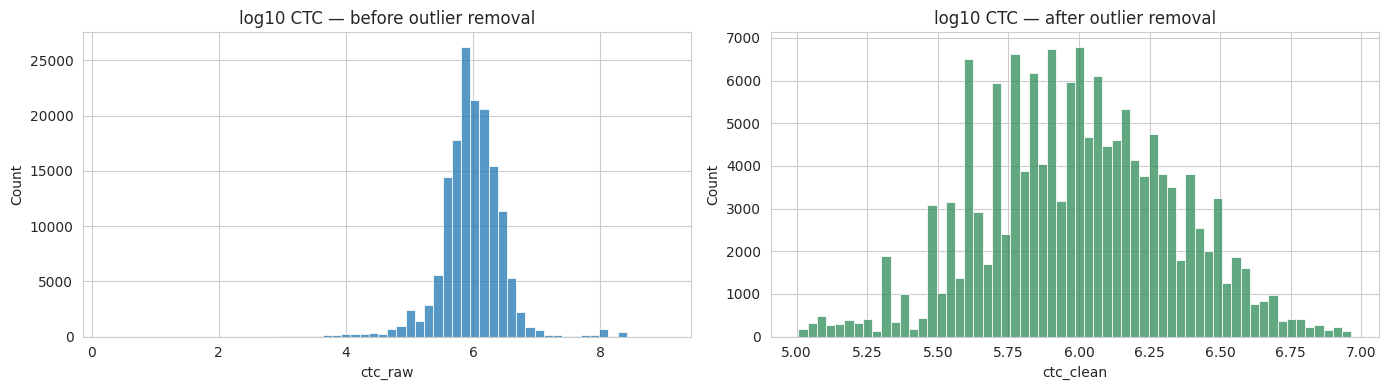

Clean CTC summary (₹ lakh):


,count,mean,std,min,25%,50%,75%,max
CTC_lakh,146297.00,13.38,11.46,1.01,6.00,10.00,17.00,92.10


In [ ]:
df["ctc_raw"] = df["ctc"].copy()
df.loc[df["ctc"] <= 0, "ctc"] = np.nan

log_ctc = np.log10(df["ctc"])
q1, q3 = log_ctc.quantile([0.25, 0.75])
iqr = q3 - q1
low_b, high_b = q1 - IQR_MULTIPLIER * iqr, q3 + IQR_MULTIPLIER * iqr
low_inr, high_inr = 10 ** low_b, 10 ** high_b
print(f"Accepted CTC range: ₹{low_inr:,.0f}  to  ₹{high_inr:,.0f}   (₹{lakh(low_inr):.2f} lakh to ₹{lakh(high_inr):.2f} lakh)")

is_outlier = df["ctc"].notna() & ~df["ctc"].between(low_inr, high_inr)
print(f"Outliers below range: {(df['ctc'] < low_inr).sum():,} | above range: {(df['ctc'] > high_inr).sum():,} "
      f"| total {is_outlier.sum():,} ({100*is_outlier.mean():.2f}% of records)")

df["ctc_was_outlier_or_invalid"] = (is_outlier | df["ctc"].isna()).astype(int)
df.loc[is_outlier, "ctc"] = np.nan          # 'ctc' now holds only trustworthy values
df = df.rename(columns={"ctc": "ctc_clean"})

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(np.log10(df["ctc_raw"].clip(lower=1)), bins=60, ax=axes[0]); axes[0].set_title("log10 CTC — before outlier removal")
sns.histplot(np.log10(df["ctc_clean"].dropna()), bins=60, ax=axes[1], color="seagreen"); axes[1].set_title("log10 CTC — after outlier removal")
plt.tight_layout(); plt.show()
print("Clean CTC summary (₹ lakh):")
d = df["ctc_clean"].describe(); d[d.index != "count"] = d[d.index != "count"] / 1e5
display(d.to_frame("CTC_lakh").T)

### Step 11 — KNN imputation (for the clustering matrix)
Missing/invalid **experience** and removed **CTC outliers** are imputed with a KNN imputer on standardised
`[log10 CTC, experience, ctc_updated_year]`. Salary **benchmarking** keeps using only trustworthy `ctc_clean` values;
the imputed CTC is used **only for clustering**. Missingness indicators are retained.

In [ ]:
knn_in = pd.DataFrame({
    "log_ctc": np.log10(df["ctc_clean"]),
    "experience": df["Years of Experience"],
    "update_year": df["ctc_updated_year"],
}, index=df.index)

print("Missing before imputation:")
display(knn_in.isna().sum().to_frame("missing"))

scaler_knn = StandardScaler()
knn_scaled = scaler_knn.fit_transform(knn_in)                 # NaNs are ignored when fitting
imputer = KNNImputer(n_neighbors=5, weights="distance")
knn_imputed = pd.DataFrame(scaler_knn.inverse_transform(imputer.fit_transform(knn_scaled)),
                           columns=knn_in.columns, index=df.index)

df["ctc_for_clustering"] = 10 ** knn_imputed["log_ctc"]
df["Years of Experience"] = knn_imputed["experience"].round().clip(lower=0, upper=REFERENCE_YEAR - MIN_VALID_ORGYEAR)
df["ctc_updated_year"] = knn_imputed["update_year"].round()

print("Missing after imputation:")
display(df[["ctc_for_clustering", "Years of Experience", "ctc_updated_year"]].isna().sum().to_frame("missing"))
print("Rows with a CTC imputed for clustering only:", int(df["ctc_clean"].isna().sum()))

Missing before imputation:


,missing
log_ctc,7146
experience,1179
update_year,0


Missing after imputation:


,missing
ctc_for_clustering,0
Years of Experience,0
ctc_updated_year,0


Rows with a CTC imputed for clustering only: 7146


### Step 12 — Encoding and standardisation

In [ ]:
# --- Encoding -----------------------------------------------------------
# job_position: category dtype + one-hot (rare roles grouped as 'Other role')
df["job_position"] = df["job_position"].astype("category")
top_roles = df["job_position"].value_counts().head(10).index
role_grouped = df["job_position"].astype(object).where(df["job_position"].isin(top_roles), "Other role")
role_onehot = pd.get_dummies(role_grouped, prefix="role", dtype=float)

# company: frequency encoding (high-cardinality, so one-hot is impractical)
company_freq = df["company_clean"].map(df["company_clean"].value_counts(normalize=True))
df["company_freq_enc"] = company_freq

print("One-hot role columns:", list(role_onehot.columns))
print("Distinct cleaned companies:", df["company_clean"].nunique())

# --- Standardisation ----------------------------------------------------
df["log_ctc_cluster"] = np.log10(df["ctc_for_clustering"])
cluster_features = ["log_ctc_cluster", "Years of Experience"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[cluster_features])
print("\nClustering matrix:", X_scaled.shape, "| finite:", np.isfinite(X_scaled).all())
print("Scaled means ~0:", X_scaled.mean(axis=0).round(3), "| std ~1:", X_scaled.std(axis=0).round(3))

# Extended matrix = scaled numerics + one-hot roles (used only for a comparison later)
X_with_roles = np.hstack([X_scaled, role_onehot.values])
print("Matrix with role encoding:", X_with_roles.shape)

One-hot role columns: ['role_Android Engineer', 'role_Backend Engineer', 'role_Data Scientist', 'role_Engineering Leadership', 'role_Frontend Engineer', 'role_FullStack Engineer', 'role_Other', 'role_Other role', 'role_QA Engineer', 'role_SDET', 'role_Unknown']
Distinct cleaned companies: 36266

Clustering matrix: (153443, 2) | finite: True
Scaled means ~0: [ 0. -0.] | std ~1: [1. 1.]
Matrix with role encoding: (153443, 13)


**Pre-processing summary**
- Company names normalised with regex (junk numeric names → `Unknown`); roles kept as a category with `Unknown` for missing.
- Invalid experience and CTC outliers excluded from benchmarking and **KNN-imputed** for clustering; missing flags retained.
- Log-transformed CTC and experience **standardised**; roles **one-hot** encoded and companies **frequency** encoded.

## Part C — Manual clustering flags
Each learner's CTC is compared with the **mean CTC of their peer group**:
`1` = above group mean, `2` = equal to group mean, `3` = below group mean.
Groups with fewer than `MIN_GROUP_SIZE` valid CTCs are marked *Insufficient data*.
Only trustworthy `ctc_clean` values are used.

In [ ]:
salary_df = df[df["ctc_clean"].notna()].copy()
print("Records available for salary benchmarking:", len(salary_df))

FLAG_ORDER = ["1", "2", "3", "Insufficient data"]

def add_group_flag(data, keys, prefix, flag_name, min_count=MIN_GROUP_SIZE):
    stats = (data.groupby(keys, observed=True, dropna=False)["ctc_clean"]
                 .agg(["mean", "median", "min", "max", "count"]).reset_index())
    stats.columns = keys + [f"{prefix}_{s}" for s in ["mean", "median", "min", "max", "count"]]
    out = data.merge(stats, on=keys, how="left", validate="many_to_one")

    enough = out[f"{prefix}_count"] >= min_count
    equal = np.isclose(out["ctc_clean"], out[f"{prefix}_mean"], rtol=1e-9, atol=1e-6)
    out[flag_name] = "Insufficient data"
    out.loc[enough & (out["ctc_clean"] > out[f"{prefix}_mean"]) & ~equal, flag_name] = "1"
    out.loc[enough & equal, flag_name] = "2"
    out.loc[enough & (out["ctc_clean"] < out[f"{prefix}_mean"]) & ~equal, flag_name] = "3"
    return out

def flag_insights(data, flag_col, title):
    summ = (data.groupby(flag_col)
                .agg(Records=("ctc_clean", "size"),
                     Median_CTC_lakh=("ctc_clean", lambda s: s.median() / 1e5),
                     Median_Experience=("Years of Experience", "median"))
                .reindex(FLAG_ORDER))
    summ["Share_%"] = 100 * summ["Records"] / summ["Records"].sum()
    display(summ)

    flagged = data[data[flag_col] != "Insufficient data"]
    above, below = (flagged[flag_col] == "1").sum(), (flagged[flag_col] == "3").sum()
    print(f"Coverage: {100*len(flagged)/len(data):.1f}% of records could be flagged.")
    print(f"Above-mean : below-mean ratio = {above:,} : {below:,}  ({below/max(above,1):.2f} below per above)")

    plt.figure(figsize=(6, 3.5))
    sns.countplot(data=data, x=flag_col, order=FLAG_ORDER, palette="viridis")
    plt.title(title); plt.show()

Records available for salary benchmarking: 146297


### Step 13 — Designation flag (company + job position + years of experience)

,Records,Median_CTC_lakh,Median_Experience,Share_%
Designation,,,,
1,23238,15.00,5.00,15.88
2,217,9.00,5.00,0.15
3,33448,6.42,4.00,22.86
Insufficient data,89394,10.00,6.00,61.10


Coverage: 38.9% of records could be flagged.
Above-mean : below-mean ratio = 23,238 : 33,448  (1.44 below per above)


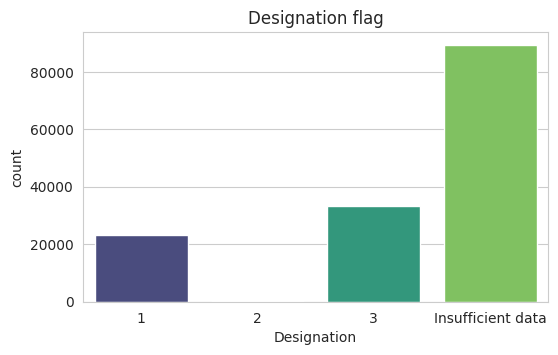

,company_clean,job_position,Years of Experience,ctc_clean,designation_mean,designation_count,Designation
0,faulwklwsl ks,Backend Engineer,6.00,2000000.00,2000000.00,1,Insufficient data
1,wirijzcsk,Backend Engineer,4.00,700000.00,952000.00,5,3
2,kllzuwdoz wzleuinita,Backend Engineer,2.00,400000.00,425000.00,2,Insufficient data
3,snhdy,Unknown,2.00,360000.00,360000.00,1,Insufficient data
4,litusqkuw,Data Analyst,5.00,440000.00,591083.25,12,3


In [ ]:
salary_df = add_group_flag(salary_df, ["company_clean", "job_position", "Years of Experience"],
                           "designation", "Designation")
flag_insights(salary_df, "Designation", "Designation flag")
display(salary_df[["company_clean", "job_position", "Years of Experience", "ctc_clean",
                   "designation_mean", "designation_count", "Designation"]].head())

**Designation — how to read it**
- This is the **tightest peer group** (same employer, role and experience), so it is the fairest pay comparison — but it is also the sparsest. Expect the largest *Insufficient data* share here.
- Learners flagged **1** earn more than peers doing the same job at the same company with the same experience (strong negotiators, specialised skills, or promotions). Learners flagged **3** are paid below that peer average — the natural audience for upskilling and job-switch support.
- Because CTC is right-skewed even within a group, the mean is pulled up by a few high earners, so **below-mean (3) will normally outnumber above-mean (1)**; that is a statistical effect, not proof that most learners are underpaid.

### Step 14 — Class flag (company + job position)

,Records,Median_CTC_lakh,Median_Experience,Share_%
Class,,,,
1,36309,18.00,6.00,24.82
2,154,10.55,5.00,0.11
3,54649,7.00,4.00,37.35
Insufficient data,55185,9.00,6.00,37.72


Coverage: 62.3% of records could be flagged.
Above-mean : below-mean ratio = 36,309 : 54,649  (1.51 below per above)


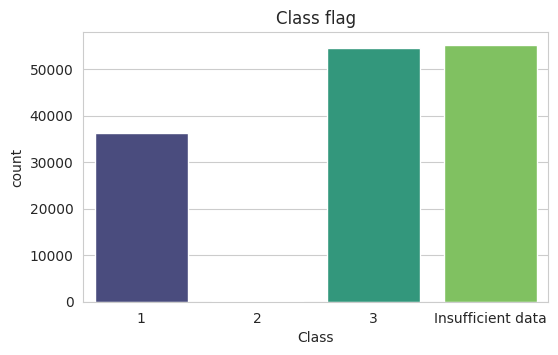

In [ ]:
salary_df = add_group_flag(salary_df, ["company_clean", "job_position"], "class", "Class")
flag_insights(salary_df, "Class", "Class flag")

**Class — how to read it**
- Dropping experience from the grouping gives **bigger peer groups and higher coverage**, but now experience itself drives the flag: senior people in a role are naturally above the class mean and juniors below it.
- So *Class 1* mixes "well-paid for the role" with "simply more experienced". Compare the median experience of Class 1 vs Class 3 in the table above to see how strong that effect is.
- Use Class when you need broad role-level benchmarks; use Designation when you need a like-for-like comparison.

### Step 15 — Tier flag (company only)

,Records,Median_CTC_lakh,Median_Experience,Share_%
Tier,,,,
1,43631,19.00,7.00,29.82
2,73,10.00,6.00,0.05
3,70454,7.10,5.00,48.16
Insufficient data,32139,8.00,6.00,21.97


Coverage: 78.0% of records could be flagged.
Above-mean : below-mean ratio = 43,631 : 70,454  (1.61 below per above)


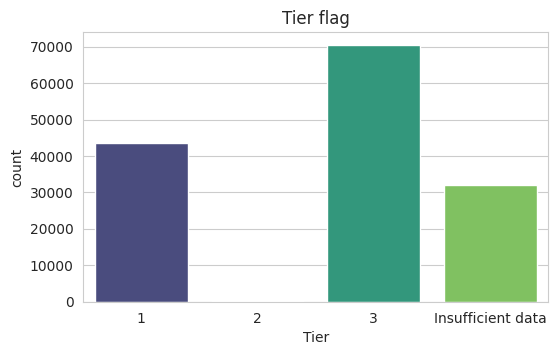

In [ ]:
salary_df = add_group_flag(salary_df, ["company_clean"], "tier", "Tier")
flag_insights(salary_df, "Tier", "Tier flag")

**Tier — how to read it**
- The widest grouping: it compares a learner with *everyone* at the same employer, so it has the highest coverage and also the most mixing of roles and seniority.
- **Tier 1** learners earn above their company average — typically senior or specialised staff. **Tier 3** learners are below the company average — typically junior or generalist staff.
- Comparing the three flags: coverage rises Designation → Class → Tier, while like-for-like fairness falls. A learner flagged 3 on *Designation* **and** 3 on *Tier* is the clearest candidate for "paid below market" outreach.

### Step 16 — Business questions answered with the flags

In [ ]:
cols = ["company_clean", "job_position", "Years of Experience", "ctc_clean"]

print("Top 10 learners above their COMPANY mean (Tier = 1):")
display(salary_df[salary_df["Tier"] == "1"].sort_values("ctc_clean", ascending=False)
        [cols + ["tier_mean", "tier_count"]].head(10))

print("Top 10 learners above their company+role mean (Class = 1):")
display(salary_df[salary_df["Class"] == "1"].sort_values("ctc_clean", ascending=False)
        [cols + ["class_mean", "class_count"]].head(10))

print("Top 10 learners above their company+role+experience mean (Designation = 1):")
display(salary_df[salary_df["Designation"] == "1"].sort_values("ctc_clean", ascending=False)
        [cols + ["designation_mean", "designation_count"]].head(10))

print(f"Top 10 companies by median CTC (at least {MIN_COMPANY_RECORDS} valid records):")
top_companies = (salary_df.groupby("company_clean")["ctc_clean"]
                 .agg(median_ctc="median", mean_ctc="mean", records="count")
                 .query("records >= @MIN_COMPANY_RECORDS")
                 .sort_values("median_ctc", ascending=False).head(10))
display(top_companies.assign(median_lakh=lambda d: d.median_ctc / 1e5).drop(columns=["median_ctc", "mean_ctc"]))

print("Top 2 job positions per company by median CTC (at least 3 records per position, companies with >= 20 records):")
big_companies = salary_df["company_clean"].value_counts()
big_companies = big_companies[big_companies >= MIN_COMPANY_RECORDS].index
cp = (salary_df[salary_df["company_clean"].isin(big_companies)]
      .groupby(["company_clean", "job_position"], observed=True)["ctc_clean"]
      .agg(median_ctc="median", records="count").reset_index().query("records >= 3"))
top2 = (cp.sort_values(["company_clean", "median_ctc"], ascending=[True, False])
          .groupby("company_clean").head(2))
display(top2.assign(median_lakh=top2.median_ctc / 1e5).drop(columns="median_ctc").head(30))

# Data-science / ML roles (keyword search is approximate)
ds_mask = salary_df["job_position"].astype(str).str.contains(
    r"data scientist|data science|machine learning|ml engineer|artificial intelligence",
    case=False, regex=True)
ds_df = salary_df[ds_mask]
print("Data-science / ML records:", len(ds_df))
print("Highest-paid:"); display(ds_df.sort_values("ctc_clean", ascending=False)[cols + ["Class"]].head(10))
print("Lowest-paid:");  display(ds_df.sort_values("ctc_clean")[cols + ["Class"]].head(10))
print("Median CTC (₹ lakh) — Data/ML roles: %.2f | all roles: %.2f" %
      (ds_df["ctc_clean"].median() / 1e5, salary_df["ctc_clean"].median() / 1e5))

Top 10 learners above their COMPANY mean (Tier = 1):


,company_clean,job_position,Years of Experience,ctc_clean,tier_mean,tier_count
48661,kcigz,Engineering Leadership,17.00,9210000.00,2610563.63,935
121459,tokg,Engineering Leadership,6.00,9200000.00,2680602.64,151
38961,giirsutlih,Backend Engineer,5.00,9200000.00,2832739.11,46
18700,cgf gkur,Backend Engineer,11.00,9200000.00,1499098.48,132
117378,kcigz,Backend Architect,7.00,9200000.00,2610563.63,935
88694,khkqiu,Engineering Leadership,13.00,9200000.00,2242147.22,2401
127125,kvsfi sul,Backend Architect,15.00,9200000.00,1789230.69,13
103658,bnsjrkow,Product Manager,9.00,9200000.00,2755948.53,719
57174,psi,Engineering Leadership,16.00,9100000.00,1844833.32,120
143705,tdkvdf,SDET,3.00,9100000.00,2437625.00,24


Top 10 learners above their company+role mean (Class = 1):


,company_clean,job_position,Years of Experience,ctc_clean,class_mean,class_count
48661,kcigz,Engineering Leadership,17.00,9210000.00,3151818.18,44
88694,khkqiu,Engineering Leadership,13.00,9200000.00,4072604.17,48
117378,kcigz,Backend Architect,7.00,9200000.00,3346962.26,53
18700,cgf gkur,Backend Engineer,11.00,9200000.00,1744499.97,34
38961,giirsutlih,Backend Engineer,5.00,9200000.00,3350000.00,30
103658,bnsjrkow,Product Manager,9.00,9200000.00,4910000.00,5
121459,tokg,Engineering Leadership,6.00,9200000.00,4692500.00,4
143705,tdkvdf,SDET,3.00,9100000.00,3735000.00,4
57174,psi,Engineering Leadership,16.00,9100000.00,3803750.00,8
139425,lswosy fafwzhf,Unknown,12.00,9100000.00,2637187.50,16


Top 10 learners above their company+role+experience mean (Designation = 1):


...

Data-science / ML records: 4418
Highest-paid:


,company_clean,job_position,Years of Experience,ctc_clean,Class
81515,fwkwz fwozzw,Data Scientist,3.00,9000000.00,Insufficient data
14077,fwosjz,Data Scientist,8.00,9000000.00,Insufficient data
110202,kkh kchs jkowa,Data Scientist,0.00,9000000.00,Insufficient data
142892,kdwiczfr,Data Scientist,2.00,8900000.00,Insufficient data
127942,nsurzcsu,Data Scientist,10.00,8500000.00,Insufficient data
47664,bnsjrkow,Data Scientist,11.00,8500000.00,1
24462,suwzoliuwsuzuwkn zylekutz,Data Scientist,2.00,8500000.00,Insufficient data
139093,xdzfw tnigkn,Data Scientist,1.00,8400000.00,Insufficient data
121283,ksogug,Data Scientist,7.00,8000000.00,Insufficient data
1939,sufjdo,Data Scientist,1.00,8000000.00,Insufficient data


Lowest-paid:


,company_clean,job_position,Years of Experience,ctc_clean,Class
136388,vsfsiuzw suwzoukwsiukn,Data Scientist,3.00,102000.00,Insufficient data
28420,duzhjniazc,Data Scientist,3.00,103000.00,Insufficient data
118649,uku,Data Scientist,6.00,107000.00,3
56226,osvzogzc wzleuinita,Data Scientist,5.00,108000.00,Insufficient data
53743,bzzcqks,Data Scientist,5.00,108500.00,Insufficient data
62784,xdkuwjes,Data Scientist,3.00,110000.00,3
45521,ukookoz,Data Scientist,4.00,110000.00,Insufficient data
115057,sucznnszuw,Data Scientist,3.00,110000.00,Insufficient data
95954,bsofwoksu,Data Scientist,5.00,110000.00,Insufficient data
135487,sloiffsut,Data Scientist,3.00,110000.00,Insufficient data


Median CTC (₹ lakh) — Data/ML roles: 12.00 | all roles: 10.00


**Insights from the business questions**
- After outlier removal the "top" lists now show **realistic compensation** instead of ₹20-crore data-entry errors, so they can be used for benchmarking.
- Company rankings use a **minimum-sample rule** (`MIN_COMPANY_RECORDS`) and medians, because a company with five records can top a mean-based ranking by chance.
- Data/ML roles are a small slice of the data; compare their median with the all-roles median above and treat conclusions as indicative rather than definitive.

## Part D — Unsupervised learning
Features: standardised **log10 CTC** and **years of experience** (outliers removed, missing values KNN-imputed).
### Step 17 — Clustering tendency (Hopkins statistic)

In [ ]:
def hopkins_statistic(X, sample_size=500, random_state=RANDOM_STATE, repeats=5):
    """Hopkins statistic on UNIQUE rows (duplicate rows would make the real-point distances 0
    and inflate the statistic towards 1). ~0.5 = random, -> 1 = clusterable."""
    X = np.unique(np.asarray(X), axis=0)
    n = len(X)
    m = int(min(sample_size, max(2, n // 10)))
    nn = NearestNeighbors(n_neighbors=2).fit(X)
    scores = []
    for r in range(repeats):
        rng = np.random.default_rng(random_state + r)
        idx = rng.choice(n, size=m, replace=False)
        w = nn.kneighbors(X[idx], n_neighbors=2)[0][:, 1]            # nearest OTHER real point
        rand_pts = rng.uniform(X.min(axis=0), X.max(axis=0), size=(m, X.shape[1]))
        u = nn.kneighbors(rand_pts, n_neighbors=1)[0][:, 0]
        scores.append(u.sum() / (u.sum() + w.sum()))
    return float(np.mean(scores)), n

h, n_unique = hopkins_statistic(X_scaled)
print(f"Hopkins statistic: {h:.3f}   (computed on {n_unique:,} unique feature rows)")
print("Reading: ~0.5 = no cluster structure; >0.75 = data is clusterable.")

Hopkins statistic: 0.928   (computed on 11,632 unique feature rows)
Reading: ~0.5 = no cluster structure; >0.75 = data is clusterable.


### Step 18 — Elbow method and silhouette scores

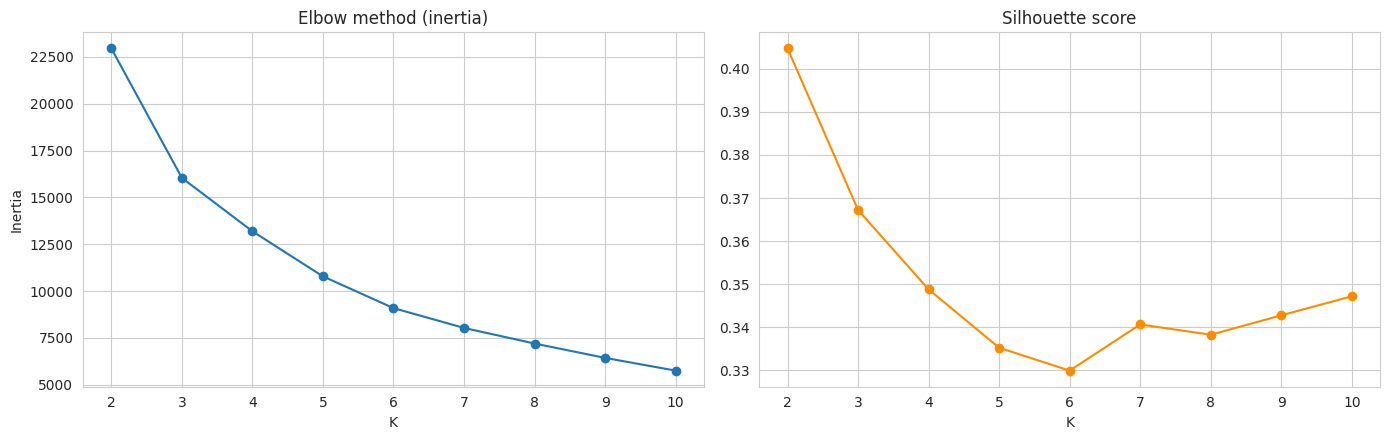

,K,Inertia,Inertia_drop_%,Silhouette
0,2,22949.59,NaN,0.41
1,3,16039.78,30.11,0.37
2,4,13192.69,17.75,0.35
3,5,10785.19,18.25,0.34
4,6,9092.97,15.69,0.33
5,7,8033.63,11.65,0.34
6,8,7201.64,10.36,0.34
7,9,6435.74,10.63,0.34
8,10,5756.83,10.55,0.35


K with the highest silhouette: 2


In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
idx_elbow = rng.choice(len(X_scaled), size=min(20000, len(X_scaled)), replace=False)
X_elbow = X_scaled[idx_elbow]
idx_sil = rng.choice(len(X_scaled), size=min(10000, len(X_scaled)), replace=False)
X_sil = X_scaled[idx_sil]

ks = list(range(2, 11))
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_elbow)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_sil, KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit_predict(X_sil)))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(ks, inertias, marker="o"); axes[0].set_title("Elbow method (inertia)")
axes[0].set_xlabel("K"); axes[0].set_ylabel("Inertia"); axes[0].set_xticks(ks)
axes[1].plot(ks, sils, marker="o", color="darkorange"); axes[1].set_title("Silhouette score")
axes[1].set_xlabel("K"); axes[1].set_xticks(ks)
plt.tight_layout(); plt.show()

sil_df = pd.DataFrame({"K": ks, "Inertia": inertias, "Inertia_drop_%": pd.Series(inertias).pct_change().mul(-100).values,
                       "Silhouette": sils})
display(sil_df.round(3))
best_k_sil = int(sil_df.loc[sil_df["Silhouette"].idxmax(), "K"])
print("K with the highest silhouette:", best_k_sil)

**How to read the elbow and silhouette plots**
- **Elbow:** inertia always falls as K rises; look for the K after which the *Inertia_drop_%* column shrinks sharply — adding more clusters beyond that point gives little extra separation.
- **Silhouette:** values around 0.3–0.5 indicate **moderate** structure; values below 0.25 mean clusters overlap heavily. Salary data is a continuum (people don't fall into sharp pay buckets), so moderate scores are expected.
- Choose K by combining both curves **and** business interpretability: 3 segments (junior / mid / senior-high pay) are easy to act on, while 6+ segments are hard to explain. Set `K_FINAL` in the configuration cell to override the automatic choice.

### Step 19 — Final K-Means model and segment profiles

K used: 2
Silhouette (10k sample): 0.406


,Segment,Learners,Median_CTC_lakh,Mean_CTC_lakh,Median_Experience,Mean_Experience,Share_with_imputed_CTC,Share_%
KMeans_Cluster,,,,,,,,
0,Lower-pay / early career,94712,6.80,7.50,4.00,4.16,0.05,61.72
1,Higher-pay / experienced,58731,19.90,22.86,9.00,9.59,0.05,38.28


Role mix within each segment (%):


job_position,Android Engineer,Backend Engineer,Data Scientist,Engineering Leadership,Frontend Engineer,FullStack Engineer,Other,Other role,QA Engineer,SDET,Unknown
Segment,,,,,,,,,,,
Higher-pay / experienced,3.20,25.80,3.50,8.80,5.50,9.30,5.30,15.30,2.70,2.40,18.20
Lower-pay / early career,2.90,18.50,2.70,0.80,5.10,12.20,10.80,13.10,4.10,3.10,26.80


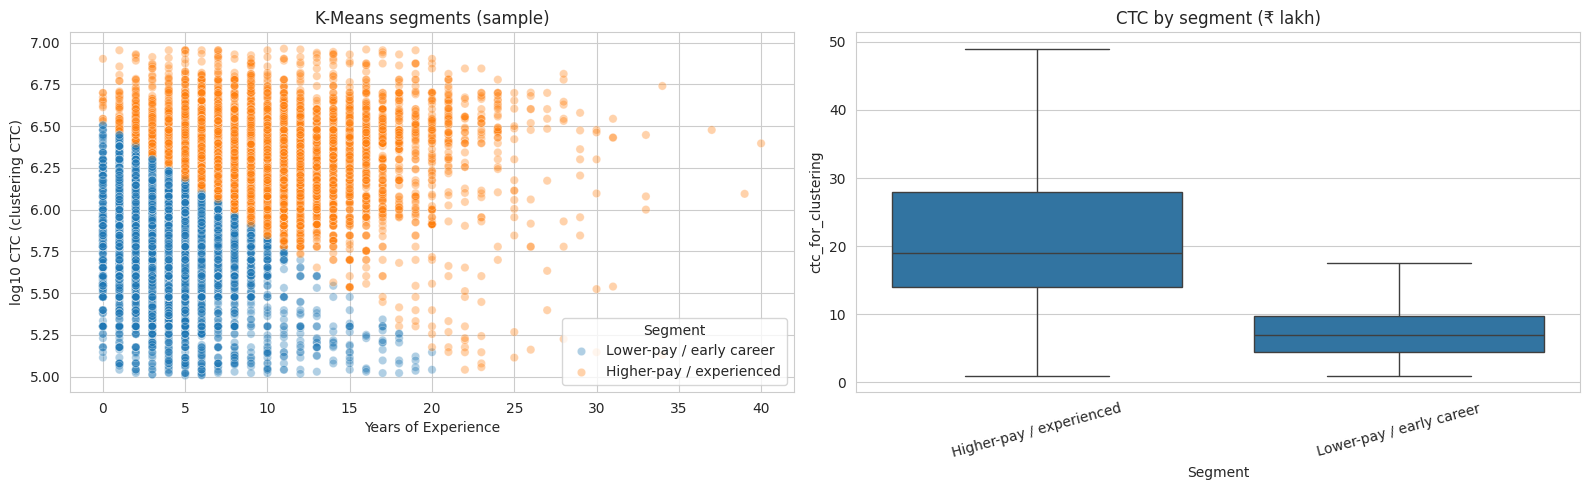

In [ ]:
best_k = K_FINAL if K_FINAL else best_k_sil
print("K used:", best_k)

kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)
print("Silhouette (10k sample):", round(silhouette_score(X_sil, df.loc[df.index[idx_sil], "KMeans_Cluster"]), 3))

def profile(data, cluster_col):
    p = (data.groupby(cluster_col)
             .agg(Learners=("ctc_for_clustering", "size"),
                  Median_CTC_lakh=("ctc_clean", lambda s: s.median() / 1e5),
                  Mean_CTC_lakh=("ctc_clean", lambda s: s.mean() / 1e5),
                  Median_Experience=("Years of Experience", "median"),
                  Mean_Experience=("Years of Experience", "mean"),
                  Share_with_imputed_CTC=("ctc_was_outlier_or_invalid", "mean")))
    p["Share_%"] = 100 * p["Learners"] / p["Learners"].sum()
    return p.sort_values("Median_CTC_lakh")

km_profile = profile(df, "KMeans_Cluster")

names = {2: ["Lower-pay / early career", "Higher-pay / experienced"],
         3: ["Early career", "Mid career", "Senior / high earners"],
         4: ["Early career", "Developing", "Established", "Senior / high earners"]}
labels = names.get(best_k, [f"Segment {i+1} (by pay rank)" for i in range(best_k)])
label_map = dict(zip(km_profile.index, labels))
df["Segment"] = df["KMeans_Cluster"].map(label_map)
km_profile.insert(0, "Segment", km_profile.index.map(label_map))
display(km_profile.round(2))

# Role mix per segment
role_mix = pd.crosstab(df["Segment"], role_grouped, normalize="index").mul(100).round(1)
print("Role mix within each segment (%):")
display(role_mix)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
samp = df.sample(min(20000, len(df)), random_state=RANDOM_STATE)
sns.scatterplot(data=samp, x="Years of Experience", y="log_ctc_cluster", hue="Segment", alpha=0.35, ax=axes[0])
axes[0].set_title("K-Means segments (sample)"); axes[0].set_ylabel("log10 CTC (clustering CTC)")
sns.boxplot(data=df, x="Segment", y=df["ctc_for_clustering"] / 1e5, showfliers=False, ax=axes[1])
axes[1].set_title("CTC by segment (₹ lakh)"); axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

**Segment interpretation**
- Segments are ordered by median CTC, so the label (early career → senior/high earners) reflects both **pay and experience**: higher-pay segments are also the more experienced ones.
- Compare **mean vs median CTC** inside each segment: a mean far above the median indicates a long tail of top earners, so use medians when quoting a "typical" salary.
- The role-mix table shows whether segments differ by job family (for example leadership roles concentrating in the senior segment).
- Does an extended feature set that also includes role one-hot columns change the structure? The next cell checks this.

In [ ]:
# Does adding the one-hot roles improve the cluster quality?
idx_cmp = idx_sil
for name, M in [("CTC + experience", X_scaled), ("CTC + experience + role one-hot", X_with_roles)]:
    lab = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10).fit_predict(M[idx_cmp])
    print(f"{name:35s} silhouette = {silhouette_score(M[idx_cmp], lab):.3f}")

CTC + experience                    silhouette = 0.405
CTC + experience + role one-hot     silhouette = 0.271


### Step 20 — Hierarchical clustering (Ward linkage, sample)

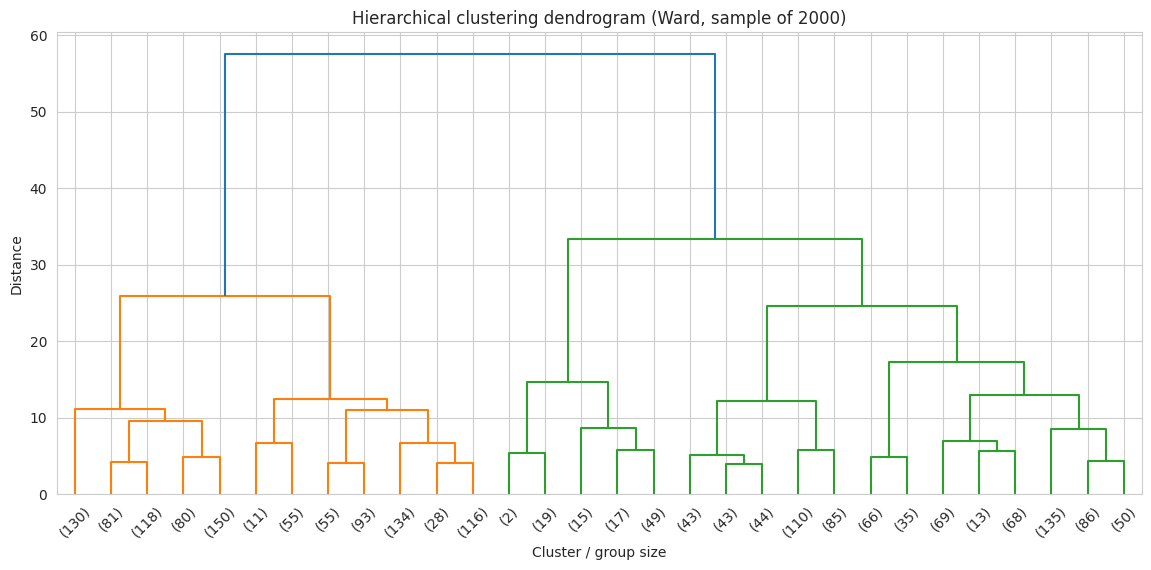

Hierarchical silhouette: 0.376


,Learners,Median_CTC_lakh,Mean_CTC_lakh,Median_Experience,Mean_Experience,Share_with_imputed_CTC,Share_%
Hierarchical_Cluster,,,,,,,
1,1051,6.00,7.02,3.00,3.55,0.06,52.55
0,949,17.00,20.64,8.00,8.96,0.05,47.45


Agreement between K-Means and hierarchical labels (Adjusted Rand Index): 0.654


In [ ]:
n_h = min(2000, len(X_scaled))
idx_h = np.random.default_rng(RANDOM_STATE).choice(len(X_scaled), size=n_h, replace=False)
X_h = X_scaled[idx_h]

Z = linkage(X_h, method="ward")
plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode="lastp", p=30)
plt.title("Hierarchical clustering dendrogram (Ward, sample of %d)" % n_h)
plt.xlabel("Cluster / group size"); plt.ylabel("Distance")
plt.show()

hier_labels = AgglomerativeClustering(n_clusters=best_k, linkage="ward").fit_predict(X_h)
print("Hierarchical silhouette:", round(silhouette_score(X_h, hier_labels), 3))

hier_df = df.iloc[idx_h].copy()
hier_df["Hierarchical_Cluster"] = hier_labels
hier_profile = profile(hier_df, "Hierarchical_Cluster")
display(hier_profile.round(2))

km_same_sample = df.iloc[idx_h]["KMeans_Cluster"].values
print("Agreement between K-Means and hierarchical labels (Adjusted Rand Index): %.3f"
      % adjusted_rand_score(km_same_sample, hier_labels))

**Comparison of the two methods**
- The **dendrogram** shows how groups merge; a long vertical gap before the final merges supports choosing that many clusters.
- If the hierarchical profile (sizes, median CTC, experience) closely resembles the K-Means profile and the **Adjusted Rand Index is high**, the segmentation is robust to the algorithm — good evidence the segments are real rather than an artefact of K-Means.
- K-Means is used for the full dataset because it scales; hierarchical clustering is used as a validation on a sample.

## Part E — Final data-quality checks

In [ ]:
print("Learners in final dataset:", len(df))
print("Duplicate learners remaining:", df["email_hash"].duplicated().sum() if DEDUPLICATE_LEARNERS else "n/a")
print("Missing in modelling columns:")
display(df[["company_clean", "job_position", "Years of Experience", "ctc_for_clustering", "KMeans_Cluster"]].isna().sum().to_frame("missing"))
print("Experience range:", df["Years of Experience"].min(), "to", df["Years of Experience"].max())
print("Valid (benchmark) CTC records:", df["ctc_clean"].notna().sum(),
      "| outliers/invalid excluded:", int(df["ctc_was_outlier_or_invalid"].sum()))

Learners in final dataset: 153443
Duplicate learners remaining: 0
Missing in modelling columns:


,missing
company_clean,0
job_position,0
Years of Experience,0
ctc_for_clustering,0
KMeans_Cluster,0


Experience range: 0.0 to 40.0
Valid (benchmark) CTC records: 146297 | outliers/invalid excluded: 7146


## Part F — Actionable insights & recommendations
The summary table below is generated from the run above, so the numbers always match the data.

In [ ]:
seg = profile(df, "KMeans_Cluster")
seg["Segment"] = seg.index.map(label_map)
summary = seg.set_index("Segment")[["Learners", "Share_%", "Median_CTC_lakh", "Median_Experience"]].round(1)
display(summary)

low, high = seg["Median_CTC_lakh"].iloc[0], seg["Median_CTC_lakh"].iloc[-1]
print(f"Largest segment: {summary['Learners'].idxmax()} ({summary['Share_%'].max():.0f}% of learners)")
print(f"Median CTC rises from ₹{low:.1f} lakh in the lowest segment to ₹{high:.1f} lakh in the highest ({high/low:.1f}x).")

below_both = salary_df[(salary_df["Designation"] == "3") & (salary_df["Tier"] == "3")]
print(f"Learners below peer mean on BOTH Designation and Tier: {len(below_both):,} "
      f"({100*len(below_both)/len(salary_df):.1f}% of benchmarkable learners) — priority audience for upskilling / job-switch support.")

,Learners,Share_%,Median_CTC_lakh,Median_Experience
Segment,,,,
Lower-pay / early career,94712,61.70,6.80,4.00
Higher-pay / experienced,58731,38.30,19.90,9.00


Largest segment: Lower-pay / early career (62% of learners)
Median CTC rises from ₹6.8 lakh in the lowest segment to ₹19.9 lakh in the highest (2.9x).
Learners below peer mean on BOTH Designation and Tier: 30,354 (20.7% of benchmarkable learners) — priority audience for upskilling / job-switch support.


### Business recommendations
1. **Segment-specific programmes.** Offer foundation, interview-prep and placement-focused tracks (with affordable or outcome-linked pricing) to the large *early-career* segment; offer system-design, architecture and leadership programmes to the *senior / high-earner* segment; use the middle segment for role-switch and specialisation tracks.
2. **Launch a salary-benchmark product** based on **medians and percentile bands (P25/P50/P75)** by role × experience band, shown only when a cell has enough records (e.g. ≥ 30). Medians avoid the distortion from the heavy right tail, and the minimum-sample rule avoids misleading numbers.
3. **Target "underpaid" learners.** Learners flagged below peer mean on both *Designation* and *Tier* are the best audience for upskilling, negotiation coaching and job-switch support — a clear "close your pay gap" message.
4. **Use the pay-progression curve in marketing,** presented as an indicative range (cross-sectional data, not a guarantee): median CTC climbs steadily with experience, and the gap between the lowest and highest segments shows the value of moving up the ladder.
5. **Prioritise employer partnerships** with companies that combine a high median CTC and a healthy sample size (see the company ranking in Step 16), and avoid ranking companies on a handful of records.
6. **Treat data/ML roles as a premium niche to validate** — compare their median with the overall median before positioning pricing; the sample is small compared with Backend/Full-Stack, which should remain the core curriculum.
7. **Fix data capture at source.** Make job position mandatory, validate CTC on entry (e.g. ₹1 lakh – ₹5 crore), validate joining year (1980 – current year), standardise company names, and prompt learners to refresh stale CTC. Keep one record per learner or timestamp every update — this alone removes most of the noise found in this notebook.

### Limitations
- Cross-sectional, self-reported data; `ctc_updated_year` mixes salaries from different years (no inflation adjustment).
- Roles are missing for a large share of learners and the "Other" role is ambiguous.
- Company names are anonymised hashes, so companies cannot be linked to real employers or industries.
- Silhouette scores are moderate: segments are useful summaries of a continuum, not sharply separated groups.

# **Key insights :**
**1. Data quality**
•	The raw file has 205,843 rows but only 153,443 unique learners. After removing 34 exact duplicates and keeping the latest record per learner, about 25% of rows were repeat updates.

•	CTC is extremely skewed: median ₹9.5 lakh, mean ₹22.7 lakh, 99th percentile ₹126 lakh and 99.9th percentile ₹20 crore. On the log scale the skew drops from 15.97 to −0.24, so log or median is the right way to analyse salary.

•	The IQR rule on log CTC accepts ₹1.01 lakh to ₹92.38 lakh and removes 7,146 records (4.66%). There are about twice as many too-low values (4,761) as too-high (2,385), which points to unit errors such as monthly pay or values entered in thousands.

•	The role field is weak: 25.5% missing and 1,016 distinct free-text values. Company has 37,299 distinct names, and the top 15 cover only 21% of records. Segmentation therefore rests on pay and experience, not on role or employer.

•	The cleaning handled 1,301 impossible joining years, 85 purely numeric company names and 1,179 learners with imputed experience.

**2. EDA relationships**
•	Experience and log CTC correlate at only 0.34 (Spearman), so experience explains part of pay but role, employer and skills matter too.

•	Experience and update year correlate at −0.26: experienced learners tend to have older salary records, and recent updates come mostly from early-career learners.

**3. Manual flags**
Flag	Coverage	Above mean (1)	Below mean (3)	Median CTC (1 vs 3)	Median experience (1 vs 3)
Designation	38.9%	15.9%	22.9%	₹15L vs ₹6.4L	5 vs 4 yrs
Class	62.3%	24.8%	37.4%	₹18L vs ₹7L	6 vs 4 yrs
Tier	78.0%	29.8%	48.2%	₹19L vs ₹7.1L	7 vs 5 yrs

•	Coverage rises from Designation to Tier, but the like-for-like comparison weakens. The experience gap between flag 1 and flag 3 widens from 1 year to 2 years, so Class and Tier increasingly measure seniority, not fair pay.

•	Outlier removal reduced the skew bias: below-mean learners now outnumber above-mean by 1.44 to 1.61 per one, down from about 1.9 to 2.9 before cleaning.

•	30,354 learners (20.7%) are below peer mean on both Designation and Tier.

•	Data/ML roles (4,418 records) have a median of ₹12L against ₹10L for all roles, a premium of roughly 20%.

•	Top company medians range ₹30 to 39 lakh, but most rest on only 20 to 41 records. dgzo (n=148, median ₹34.25L) is the most reliable.

**4. Clustering **
•	The clustering tendency is strong: Hopkins 0.928 on unique rows.

•	Silhouette is highest at K=2 (0.41) and falls to 0.37 at K=3. The elbow shows a clear drop of about 30% at K=3, then smaller drops of 15 to 18% at K=4 to 6.

Segment	Learners	Median CTC	Mean CTC	Median experience
Lower-pay / early career	94,712 (61.7%)	₹6.8L	₹7.5L	4 yrs
Higher-pay / experienced	58,731 (38.3%)	₹19.9L	₹22.9L	9 yrs

•	Median pay is 2.9× higher in the experienced segment. Engineering Leadership is 8.8% of that segment against 0.8% of the early-career one.

•	Adding role one-hot columns drops silhouette from 0.405 to 0.271, so pay and experience define the segments, not job family.

•	Hierarchical clustering gives a similar split (medians ₹6L and ₹17L; silhouette 0.376), and agreement with K-Means is ARI = 0.654. The segments are reasonably robust but share a fuzzy boundary, since pay is a continuum.


# **Business recommendations**
**1.	Run two track families. **
o	Evidence: 61.7% of learners are early-career, with a ₹6.8L median at 4 years.

o	Action: build placement and interview-prep programmes for them, with affordable or outcome-linked pricing.

o	For the experienced 38.3% (₹19.9L median), build leadership and system-design programmes. Leadership roles are 11 times more concentrated there.

**2.	Launch a salary-benchmark tool with a fallback chain. **
o	Evidence: Designation covers only 38.9% of learners, Class 62.3% and Tier 78%.

o	Action: show median and P25/P75 bands at Designation level when there are enough peers, then fall back to Class and Tier, labelling the comparison level clearly.

**3.	Target the “paid below peers” group.**
o	Evidence: 30,354 learners (20.7%) are below peer mean on both Designation and Tier, and Designation-3 learners have a median of ₹6.4L against ₹15L for Designation-1.

o	Action: offer upskilling, negotiation coaching and job-switch support. Describe them as “paid below peers”, not “underpaid”, since the flag is mean-based.

**4.	Use the pay-progression story in marketing. **
o	Evidence: median pay is 2.9× higher at about 9 years than at about 4.

o	Action: present it as an indicative range from cross-sectional data, not a guaranteed outcome.

**5.	Prioritise employer partnerships by sample size. **
o	Evidence: the top median companies are mostly based on 20 to 41 records.

o	Action: start with dgzo (n=148) and validate the others with more data before building outreach around them.

**6.	Position data/ML as a moderate premium. **
o	Evidence: a median of ₹12L against ₹10L overall, from about 3% of records.

o	Action: price it as a modest premium and test demand before a large investment. Backend and Full-Stack remain the core volume.

**7.	Fix data capture. **
o	Evidence: 25.5% missing roles, 1,016 free-text role values, 4.66% out-of-range CTC and 25% repeated rows.

o	Action: use a role dropdown, add CTC range checks and unit labels (annual, in ₹), validate joining year, and timestamp or de-duplicate profile updates.

**Limitations**
•	The data is self-reported and cross-sectional, with no inflation adjustment across update years.

•	Outlier removal caps the top end at ₹92 lakh, so true top earners are excluded.

•	Company names are anonymised, and role is missing for a quarter of learners.

•	Silhouette of about 0.4 means the segments are useful summaries of a continuum, not sharply separated groups.


In [ ]:
!ls

sample_data


In [8]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:
!jupyter nbconvert --to html "/content/drive/MyDrive/Colab Notebooks/Scaler_Clustering_Heena"

[NbConvertApp] Converting notebook /content/drive/MyDrive/Colab Notebooks/Scaler_Clustering_Heena.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 9 image(s).
[NbConvertApp] Writing 1634750 bytes to /content/drive/MyDrive/Colab Notebooks/Scaler_Clustering_Heena.html
